# EDA Document For Derived MIMIC-IV Ver 3.1

****
**FOR DEEP LEARNING CLASS E-EN Group 5 Only**

This document provides the full exploratory data analysis of the physionet's MIMIC-IV Dataset. Please consider that this document is confidential and cannot be shared between peers without its owner permission. Regarding that, the main Physionet's MIMIC-IV 3.1 Dataset needs the holder to have been certificated through its website.

Sincerely,
Winata's Group

## 0. Import the Parquet

In [ ]:
import os
import numpy as np
DRIVE_PATH = "/content/drive/MyDrive/datasets/sepsis_physionet/physionet_style_hourly.parquet"

if not os.path.exists("/content/drive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass

import pandas as pd
df = pd.read_parquet(DRIVE_PATH)
print(f"loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DRIVE_PATH}")

df = df.rename(columns={"SepsisLabel": "SepsisLabel_raw_broadcast"})  # keep for debugging, never train on it

# 1. Define the 6-hour prediction window strictly
df["SepsisLabel"] = ((df["HoursToOnset"] >= 0) & (df["HoursToOnset"] <= 6)).astype(np.int32)

# 2. Drop all post-onset rows (HoursToOnset < 0) to prevent treatment leakage
# isna() ensures your non-septic control patients are kept intact
df = df[df["HoursToOnset"].isna() | (df["HoursToOnset"] >= 0)].copy()

print(f"Left with {df.shape[0]:,} rows x {df.shape[1]} columns from {DRIVE_PATH}")

Mounted at /content/drive
loaded 7,379,165 rows x 64 columns from /content/drive/MyDrive/datasets/sepsis_physionet/physionet_style_hourly.parquet
Left with 3,966,669 rows x 65 columns from /content/drive/MyDrive/datasets/sepsis_physionet/physionet_style_hourly.parquet


## 1. Load & Structural Overview

In [ ]:
import numpy as np, matplotlib.pyplot as plt

SUBJECT_COL = "subject_id"
ID_COL = "stay_id"
HOUR_COL = "ICULOS"
LABEL_COL = "SepsisLabel"

PHYSIONET_REF = {
    "n_patients": 40336, "n_rows": 1_552_210, "row_positive_rate": 0.018,
    "patient_positive_rate": 0.0727, "median_los_hours": 38.5, "overall_missingness": 0.70,
}

print(df.shape)
print(df.dtypes)
print(f"{df[SUBJECT_COL].nunique()} patients, {df[ID_COL].nunique()} ICU stays")

(3966669, 65)
subject_id           int32
stay_id              int32
HR                 float64
O2Sat              float64
Temp               float64
                    ...   
HoursSinceSusp     float64
SepsisStay           int32
SepsisOnsetHour    float64
HoursToOnset       float64
SepsisLabel          int32
Length: 65, dtype: object
56075 patients, 74704 ICU stays


## 2. Row-Level and Patient-Level Sepsis Prevalence
*****
The first real decision-relevant number: how rare is the positive class here, and does it match PhysioNet closely enough that your focal-loss settings and performance-gate thresholds transfer, or need re-tuning for this cohort.

In [ ]:
row_pos_rate = df[LABEL_COL].mean()
stay_pos = df.groupby(ID_COL)[LABEL_COL].max()
subj_pos = df.groupby(SUBJECT_COL)[LABEL_COL].max()

print(f"row-level positive rate: {row_pos_rate:.4f}  (PhysioNet ref: {PHYSIONET_REF['row_positive_rate']})")
print(f"stay-level positive rate: {stay_pos.mean():.4f}")
print(f"patient-level positive rate: {subj_pos.mean():.4f}  (PhysioNet ref: {PHYSIONET_REF['patient_positive_rate']})")

row-level positive rate: 0.0115  (PhysioNet ref: 0.018)
stay-level positive rate: 0.1570
patient-level positive rate: 0.1884  (PhysioNet ref: 0.0727)


## 3. Sequence Length Distribution
****
Decides your max sequence length / padding strategy, and whether MIMIC-IV stays run notably longer or shorter than PhysioNet's ~38–39h median (that changes how much your causal-masking "growing pool" concern actually bites in practice).

count    74704.000000
mean        53.098482
std         55.586248
min          1.000000
25%         21.000000
50%         35.000000
75%         67.000000
max        336.000000
Name: ICULOS, dtype: float64


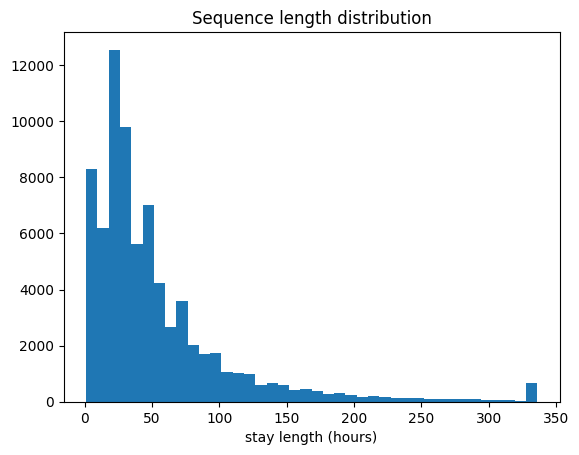

In [ ]:
seq_len = df.groupby(ID_COL)[HOUR_COL].max()
print(seq_len.describe())
fig, ax = plt.subplots(); ax.hist(seq_len, bins=40)
ax.set_xlabel("stay length (hours)"); ax.set_title("Sequence length distribution")
plt.show()

## 4. Missingness Analysis (per-feature and overall)
****
Directly feeds the embedding design: which features need the strongest decay-imputation treatment, and whether MIMIC-IV's overall missingness is close enough to PhysioNet's ~70% that the same embedding capacity split (ρ, ς) is still reasonable, or needs re-tuning.

In [ ]:
CATEGORIES = {
    "core_physionet_40": ["HR","O2Sat","Temp","SBP","MAP","DBP","Resp","EtCO2","BaseExcess","HCO3",
        "FiO2","pH","PaCO2","SaO2","AST","BUN","Alkalinephos","Calcium","Chloride","Creatinine",
        "Bilirubin_direct","Glucose","Lactate","Magnesium","Phosphate","Potassium","Bilirubin_total",
        "TroponinI","Hct","Hgb","PTT","WBC","Fibrinogen","Platelets","Age","Gender","Unit1","Unit2",
        "HospAdmTime","ICULOS","SepsisLabel"],
    "sofa_components": ["SOFA_total","SOFA_resp","SOFA_coag","SOFA_liver","SOFA_cv","SOFA_cns","SOFA_renal","SOFA_delta"],
    "treatment_indicators": ["OnVent","Norepi","Epi","Dopa","Dobu"],
    "severity_markers": ["GCS","UrineOut_mL","PF_ratio"],
    "sepsis_timing_engineering": ["SuspInfection","HoursSinceSusp","SepsisStay","SepsisOnsetHour","HoursToOnset"],
}
for cat, cols in CATEGORIES.items():
    present = [c for c in cols if c in df.columns]
    if not present: continue
    print(f"\n-- {cat}: {len(present)}/{len(cols)} present --")
    print(df[present].isna().mean().sort_values(ascending=False))


-- core_physionet_40: 41/41 present --
TroponinI           1.000000
Bilirubin_direct    0.998874
Fibrinogen          0.992610
EtCO2               0.990400
Alkalinephos        0.985630
Bilirubin_total     0.985591
AST                 0.985297
SaO2                0.980370
Lactate             0.969946
PTT                 0.953451
PaCO2               0.952137
BaseExcess          0.952131
pH                  0.946342
Calcium             0.942164
Phosphate           0.941611
WBC                 0.937719
Magnesium           0.936813
Platelets           0.936704
HCO3                0.934850
BUN                 0.934233
Creatinine          0.934011
Hgb                 0.928395
Chloride            0.925712
Hct                 0.919636
FiO2                0.915379
Glucose             0.915018
Potassium           0.910460
Temp                0.730947
Unit1               0.714337
Unit2               0.714337
DBP                 0.156306
SBP                 0.156182
MAP                 0.141657
O2S

## 5. Measurement-Density vs. Label Correlation
****
The informative-missingness check — does the number of things measured this hour leak information about the label independent of the actual values? This is the same check you ran on PhysioNet (~0.014–0.036); a big jump here on MIMIC-IV would be a real confound to flag before training.

In [ ]:
feature_cols = CATEGORIES["core_physionet_40"][:-3]  # exclude Age/Gender/HospAdmTime/ICULOS/SepsisLabel-type non-measurements if present
feature_cols = [c for c in feature_cols if c in df.columns]
density = df[feature_cols].notna().sum(axis=1)
corr = np.corrcoef(density, df[LABEL_COL])[0, 1]
print(f"density-label correlation: {corr:.4f}  (PhysioNet ref ~0.014-0.036)")

density-label correlation: 0.0457  (PhysioNet ref ~0.014-0.036)


## 6. Feature Completeness vs. the 40 PhysioNet Indicators

****
Confirms exactly which of the 40 original features exist in your MIMIC-IV extraction, so nothing is silently missing from the model without you knowing.

In [ ]:
for cat, cols in CATEGORIES.items():
    present = [c for c in cols if c in df.columns]
    missing_cols = [c for c in cols if c not in df.columns]
    print(f"{cat}: {len(present)}/{len(cols)} present | missing: {missing_cols}")

core_physionet_40: 41/41 present | missing: []
sofa_components: 8/8 present | missing: []
treatment_indicators: 5/5 present | missing: []
severity_markers: 3/3 present | missing: []
sepsis_timing_engineering: 5/5 present | missing: []


## 7. Label Timing Sanity Checks (leakage guards)
****
Checks the two specific leakage traps already flagged for this project: patients who are septic essentially on arrival (label=1 in the first few hours, which behaves differently from onset-during-stay), and whether ICULOS itself is suspiciously correlated with the label (confirming why it stays out of your severity composite).

In [ ]:
onset_hour = df[df[LABEL_COL] == 1].groupby(ID_COL)[HOUR_COL].min()
print(f"fraction of ever-positive stays positive by hour 3: {(onset_hour <= 3).mean():.3f}")
print(f"ICULOS-label correlation: {df[[HOUR_COL, LABEL_COL]].corr().iloc[0,1]:.4f}")

fraction of ever-positive stays positive by hour 3: 0.629
ICULOS-label correlation: -0.0232


## 8. Demographic & Static Feature Distributions
****
Basic cohort characterization (age, gender, unit) — mostly for your writeup's "Table 1," and to catch any obviously broken static-feature extraction before it touches the model.

In [ ]:
static = df.groupby(SUBJECT_COL).agg(Age=("Age","first"), Gender=("Gender","first"))
print(static["Age"].describe())
print(static["Gender"].value_counts(normalize=True))

count    56075.000000
mean        63.111262
std         17.004423
min         18.000000
25%         53.000000
50%         65.000000
75%         76.000000
max         91.000000
Name: Age, dtype: float64
Gender
1    0.563674
0    0.436326
Name: proportion, dtype: float64


## 9. Chronological Ordering Reconstruction & Temporal Split Feasibility
****
The one from our last conversation, done precisely: MIMIC-IV only gives you a real 3-year bucket (anchor_year_group) plus a fake per-patient anchor point (anchor_year) — the correct reconstruction adds each admission's offset from that anchor point onto the real bucket's midpoint, not just splicing the fake year directly. This cell builds that approximate real date, sorts patients by it, and assigns your TRAIN/LOC/CONF/EXT buckets chronologically — then immediately checks whether prevalence drifts oddly across buckets, which is worth knowing before you trust CONF/EXT results.

### 9a.Fetch Timing/Outcome Metadata

In [ ]:
import duckdb
import pandas as pd

MIMIC_IV_DB_PATH = '/content/drive/MyDrive/datasets/sepsis_physionet/mimic4.db'

con = duckdb.connect(MIMIC_IV_DB_PATH)

# Add the 'mimiciv_hosp.' prefix to both the patients and admissions tables
meta = con.execute("""
    SELECT p.subject_id, p.anchor_year, p.anchor_year_group,
           a.hadm_id, a.admittime, a.hospital_expire_flag
    FROM mimiciv_hosp.patients p
    JOIN mimiciv_hosp.admissions a ON p.subject_id = a.subject_id
""").df()

# one row per subject for timing purposes: use their earliest admission
subj_meta = (meta.sort_values("admittime")
                 .groupby("subject_id")
                 .first()
                 .reset_index())

print(subj_meta.shape, subj_meta.columns.tolist())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(223452, 6) ['subject_id', 'anchor_year', 'anchor_year_group', 'hadm_id', 'admittime', 'hospital_expire_flag']


### 9b.

In [ ]:
def parse_group_mid(g):
    a, b = g.split(" - ")
    return (int(a) + int(b)) / 2

subj_meta["anchor_mid"] = subj_meta["anchor_year_group"].apply(parse_group_mid)
subj_meta["year_offset"] = subj_meta["admittime"].dt.year - subj_meta["anchor_year"]
subj_meta["approx_year"] = subj_meta["anchor_mid"] + subj_meta["year_offset"]
subj_meta["approx_date"] = pd.to_datetime(dict(
    year=subj_meta["approx_year"].astype(int),
    month=subj_meta["admittime"].dt.month,
    day=subj_meta["admittime"].dt.day.clip(upper=28),
))
subj_meta = subj_meta.sort_values("approx_date").reset_index(drop=True)

n = len(subj_meta)
b1, b2, b3 = int(0.70*n), int(0.80*n), int(0.95*n)
subj_meta["split"] = np.array(["TRAIN"]*b1 + ["LOC"]*(b2-b1) + ["CONF"]*(b3-b2) + ["EXT"]*(n-b3))
print(subj_meta["split"].value_counts())

df = df.merge(subj_meta[[SUBJECT_COL, "split"]], on=SUBJECT_COL, how="left")

# exclusivity check — must never fail
assert (df.groupby(SUBJECT_COL)["split"].nunique() == 1).all(), "a patient spans multiple splits!"
print(df.groupby("split")[LABEL_COL].mean())

split
TRAIN    156416
CONF      33518
LOC       22345
EXT       11173
Name: count, dtype: int64
split
CONF     0.010411
EXT      0.011247
LOC      0.010726
TRAIN    0.011834
Name: SepsisLabel, dtype: float64


## 10. Multi-Horizon Label Availability (for the t+1/t+2 heads)
****
Since predicting SepsisLabel[t+2] needs two more hours of stay past t, hours near the end of a stay can't supply both targets. This checks how much training signal you actually lose to that truncation — and, more importantly, whether it's disproportionately cutting off positive hours (which tend to cluster later in a stay), which would quietly bias your training distribution if ignored.

In [ ]:
max_hour = df.groupby(ID_COL)[HOUR_COL].transform("max")
valid_t1 = (df[HOUR_COL] + 1) <= max_hour
valid_t2 = (df[HOUR_COL] + 2) <= max_hour
print(f"valid t+1: {valid_t1.mean():.3f}  valid t+2: {valid_t2.mean():.3f}")
print(f"positive rate, t+2-valid rows: {df.loc[valid_t2, LABEL_COL].mean():.4f}")

valid t+1: 0.981  valid t+2: 0.963
positive rate, t+2-valid rows: 0.0069


## 11. Severity Validation (SOFA vs. mortality)

In [ ]:
pat = df.groupby(SUBJECT_COL)["SOFA_total"].max().to_frame()
pat = pat.join(subj_meta.set_index(SUBJECT_COL)["hospital_expire_flag"])
pat["sofa_bin"] = pd.cut(pat["SOFA_total"], bins=[-1,5,10,15,24])
print(pat.groupby("sofa_bin", observed=True)["hospital_expire_flag"].mean())

sofa_bin
(-1, 5]     0.036687
(5, 10]     0.066820
(10, 15]    0.126199
(15, 24]    0.259362
Name: hospital_expire_flag, dtype: float64


## 12. Class Imbalance Summary

In [ ]:
print(f"row-level positive rate: {row_pos_rate:.4f}")
print(f"suggested focal-loss alpha: {1 - row_pos_rate:.3f}")

row-level positive rate: 0.0115
suggested focal-loss alpha: 0.989


## 13. HoursToOnset Lead-Time Feasibility

In [ ]:
has_onset = df["HoursToOnset"].notna()
print(df.loc[has_onset, "HoursToOnset"].describe())
for lead in [1, 6, 12, 24]:
    target = ((df["HoursToOnset"] >= 0) & (df["HoursToOnset"] <= lead)).astype(int)
    print(f"lead<= {lead}h positive rate: {target.mean():.4f}")

count    311855.000000
mean         62.216621
std          61.551288
min           0.000000
25%          14.000000
50%          43.000000
75%          92.000000
max         334.000000
Name: HoursToOnset, dtype: float64
lead<= 1h positive rate: 0.0044
lead<= 6h positive rate: 0.0115
lead<= 12h positive rate: 0.0180
lead<= 24h positive rate: 0.0281


## 14. PipelPipeline Diagram

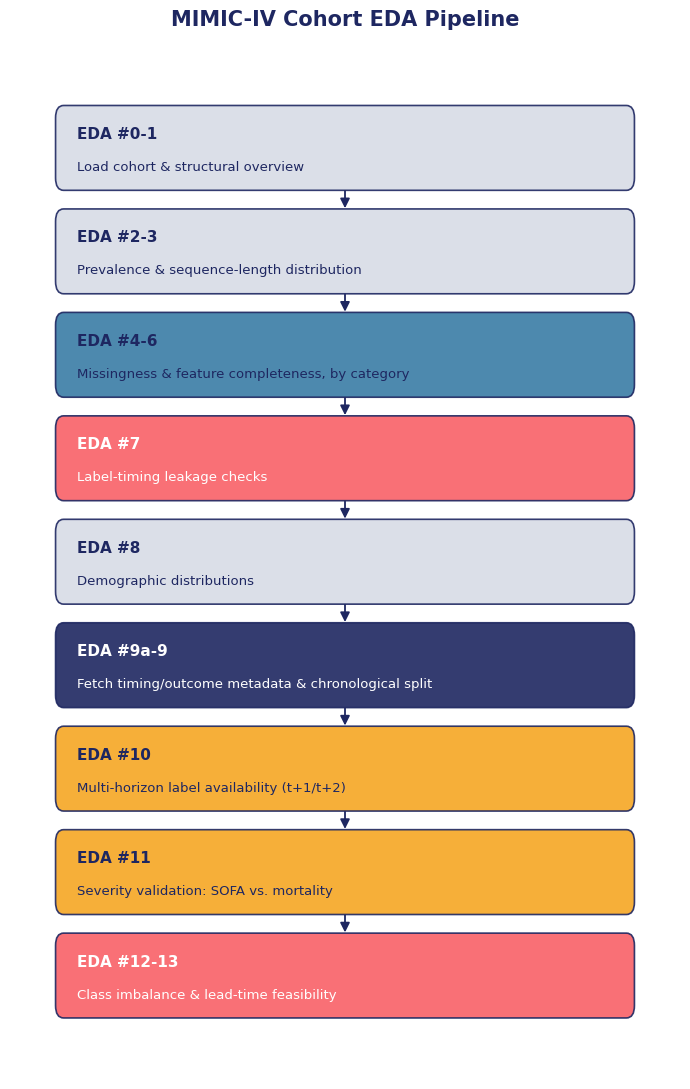

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

NAVY, CORAL, TEAL, GRAY, AMBER = "#1E2761", "#F96167", "#3A7CA5", "#D7DCE6", "#F5A623"
stages = [
    ("EDA #0-1", "Load cohort & structural overview", GRAY),
    ("EDA #2-3", "Prevalence & sequence-length distribution", GRAY),
    ("EDA #4-6", "Missingness & feature completeness, by category", TEAL),
    ("EDA #7", "Label-timing leakage checks", CORAL),
    ("EDA #8", "Demographic distributions", GRAY),
    ("EDA #9a-9", "Fetch timing/outcome metadata & chronological split", NAVY),
    ("EDA #10", "Multi-horizon label availability (t+1/t+2)", AMBER),
    ("EDA #11", "Severity validation: SOFA vs. mortality", AMBER),
    ("EDA #12-13", "Class imbalance & lead-time feasibility", CORAL),
]
fig, ax = plt.subplots(figsize=(7, 11)); ax.set_xlim(0,10); ax.set_ylim(0,len(stages)+1); ax.axis("off")
box_w, box_h = 8.6, 0.78
for i, (tag, desc, color) in enumerate(stages):
    y = len(stages) - i
    ax.add_patch(FancyBboxPatch((0.7, y-box_h/2), box_w, box_h,
        boxstyle="round,pad=0.02,rounding_size=0.12", linewidth=1.2,
        edgecolor=NAVY, facecolor=color, alpha=0.9))
    tc = "white" if color in (NAVY, CORAL) else NAVY
    ax.text(1.0, y+0.14, tag, fontsize=11, fontweight="bold", color=tc, va="center")
    ax.text(1.0, y-0.18, desc, fontsize=9.5, color=tc, va="center")
    if i < len(stages)-1:
        ax.add_patch(FancyArrowPatch((5.0, y-box_h/2), (5.0, y-1+box_h/2),
            arrowstyle="-|>", mutation_scale=14, color=NAVY, linewidth=1.3))
ax.set_title("MIMIC-IV Cohort EDA Pipeline", fontsize=15, fontweight="bold", color=NAVY, pad=14)
plt.tight_layout()
plt.savefig("eda_pipeline_diagram.png", dpi=200, bbox_inches="tight")